# 00 การเตรียมข้อมูล: Sentinel-1 SAR สำหรับแผนที่น้ำท่วม อ.กงไกรลาศ และ อ.บางระกำ

**ชุดการสอน:** Teach_SAR_flood_Mapping_ML (00–05)
**ผู้เรียน:** นิสิตวิทยาศาสตร์สิ่งแวดล้อม ป.ตรี ปี 3–4 และ ป.โท
**เวลาโดยประมาณ:** 60–90 นาที

## จุดประสงค์
เมื่อจบ notebook นี้ นิสิตจะสามารถ
1. ตั้งค่า Google Earth Engine (GEE) ด้วย project ของตนเองใน Colab
2. อธิบายได้ว่าชุดข้อมูลแต่ละตัวในบทเรียนคืออะไร มาจากไหน ละเอียดเท่าไร
3. ตรวจ metadata ของภาพ Sentinel-1 ก่อนนำไปเปรียบเทียบกัน (วันที่ ทิศการโคจร relative orbit)
4. ส่งออกข้อมูลเป็น GeoTIFF ขนาดเล็กพอที่จะเก็บใน GitHub

## กรณีศึกษา
- **พื้นที่:** อ.กงไกรลาศ (จ.สุโขทัย) และ อ.บางระกำ (จ.พิษณุโลก) ที่ราบลุ่มแม่น้ำยม
- **ภาพน้ำท่วม:** 17 ต.ค. 2017 **ภาพอ้างอิง (ไม่ท่วม):** 9 ม.ค. 2018
- ภาพอ้างอิงถ่าย *หลัง* เหตุการณ์ จึงเรียกว่า "ภาพอ้างอิง" ไม่ใช่ "ภาพก่อนน้ำท่วม"

> **หมายเหตุ:** notebook 01–05 อ่านข้อมูลจากโฟลเดอร์ `data/` ใน GitHub ได้โดยตรง นิสิตจึงไม่จำเป็นต้องส่งออกข้อมูลเอง (`RUN_EXPORT = False`) แต่ควรรันส่วนที่ 1–4 เพื่อเข้าใจที่มาของข้อมูล

## 1. ก่อนเริ่ม: สร้าง GEE project ของตนเอง

ทำครั้งเดียว แล้วใช้ได้ทุก notebook
1. สมัครใช้งานที่ https://earthengine.google.com ด้วยบัญชี Google
2. ไปที่ https://console.cloud.google.com แล้วสร้าง project ใหม่ (ตั้งชื่อเอง เช่น `ee-ชื่อนิสิต`)
3. ลงทะเบียน project สำหรับ Earth Engine แบบ **noncommercial** ที่ https://code.earthengine.google.com/register
4. ตรวจว่าเปิด **Earth Engine API** ให้ project แล้ว
5. คัดลอก **Project ID** (ไม่ใช่ชื่อ project) มาใส่ในตัวแปร `PROJECT_ID` ด้านล่าง

In [14]:
!pip -q install rasterio

In [15]:
import os, time
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import rasterio
import warnings
import ee, geemap

warnings.filterwarnings('ignore', category=DeprecationWarning)   # ซ่อนคำเตือนชุดข้อมูลรุ่นเก่าของ GEE

PROJECT_ID = 'teach-gee-github-sar'   # <-- แก้เป็น Project ID ของนิสิต

ee.Authenticate()
ee.Initialize(project=PROJECT_ID)
print('เชื่อมต่อ Earth Engine สำเร็จ:', PROJECT_ID)

เชื่อมต่อ Earth Engine สำเร็จ: teach-gee-github-sar


## 2. ตั้งค่าพารามิเตอร์

รวมค่าที่ปรับได้ไว้ที่เดียว ถ้าต้องการทำซ้ำกับพื้นที่หรือเหตุการณ์อื่น แก้เฉพาะเซลล์นี้

In [16]:
PROVINCES  = ['Sukhothai', 'Phitsanulok']     # ชื่อจังหวัดตามฐานข้อมูล FAO GAUL
AMPHOES    = ['Kong Krailat', 'Bang Rakam']   # ชื่ออำเภอตาม FAO GAUL (ตรวจการสะกดในส่วนที่ 3)

FLOOD_DATE = '2017-10-17'   # ภาพน้ำท่วม
REF_DATE   = '2018-01-09'   # ภาพอ้างอิง

CRS        = 'EPSG:32647'   # UTM zone 47N หน่วยเมตร เหมาะกับการคำนวณพื้นที่
S1_SCALE   = 10             # เมตร ถ้าไฟล์ใหญ่เกิน 50 MB ให้เปลี่ยนเป็น 20

DRIVE_FOLDER = 'Teach_SAR_flood_data'   # โฟลเดอร์ใน Google Drive ที่รับไฟล์ส่งออก
OUT_DIR      = '/content/data'          # โฟลเดอร์ผลลัพธ์สุดท้าย (นำขึ้น GitHub)
#RUN_EXPORT   = True                    # ผู้สอนตั้งเป็น True เมื่อต้องการส่งออกข้อมูลจริง
RUN_EXPORT   = False                    # ผู้สอนตั้งเป็น True เมื่อต้องการส่งออกข้อมูลจริง

## 3. ขอบเขตพื้นที่ศึกษา

ใช้ขอบเขตการปกครองจาก **FAO GAUL 2015** ซึ่งมีใน GEE อยู่แล้ว ข้อดีคือใช้ได้ทันที ข้อจำกัดคือเส้นขอบหยาบกว่าข้อมูลทางการของไทย งานวิจัยจริงควรใช้ขอบเขตจากกรมการปกครองหรือหน่วยงานที่เกี่ยวข้อง

GEE แจ้งว่าชุดข้อมูลนี้มีรุ่นใหม่กว่าคือ GAUL 2025 แต่ชื่อคอลัมน์และการสะกดชื่ออำเภอต่างออกไป บทเรียนจึงยังใช้รุ่น 2015 ซึ่งตรวจแล้วว่าใช้งานได้

เซลล์แรกพิมพ์รายชื่ออำเภอทั้งหมดในสองจังหวัด เพื่อตรวจว่าการสะกดใน `AMPHOES` ตรงกับฐานข้อมูล

In [17]:
gaul2 = (ee.FeatureCollection('FAO/GAUL/2015/level2')
         .filter(ee.Filter.eq('ADM0_NAME', 'Thailand'))
         .filter(ee.Filter.inList('ADM1_NAME', PROVINCES)))

for p in PROVINCES:
    names = gaul2.filter(ee.Filter.eq('ADM1_NAME', p)).aggregate_array('ADM2_NAME').getInfo()
    print(p, ':', sorted(names))

Sukhothai : ['Ban Dan Lan Hoi', 'Khiri Mat', 'Kong Krailat', 'Muang Sukhothai', 'Sawankhalok', 'Si Nakhon', 'Si Samrong', 'Si Satchnalai', 'Thung Saliam']
Phitsanulok : ['Bang Krathum', 'Bang Rakam', 'Chat Trakan', 'Muang Phitsanulok', 'Nakhon Thai', 'Noen Maprang', 'Phrom Phiram', 'Wang Thong', 'Wat Bot']


In [18]:
amphoe = gaul2.filter(ee.Filter.inList('ADM2_NAME', AMPHOES))
found = amphoe.aggregate_array('ADM2_NAME').getInfo()
assert len(found) == len(AMPHOES), (
    f'พบ {found} ไม่ครบตาม {AMPHOES} ให้แก้การสะกดใน AMPHOES ตามรายชื่อด้านบน')

province = (ee.FeatureCollection('FAO/GAUL/2015/level1')
            .filter(ee.Filter.eq('ADM0_NAME', 'Thailand'))
            .filter(ee.Filter.inList('ADM1_NAME', PROVINCES)))

aoi = amphoe.geometry()
area_km2 = aoi.area(1).divide(1e6).getInfo()
print(f'พื้นที่ศึกษา: {area_km2:,.0f} ตร.กม. = {area_km2 * 625:,.0f} ไร่')

พื้นที่ศึกษา: 1,412 ตร.กม. = 882,226 ไร่


## 4. ภาพ Sentinel-1 และการตรวจ metadata

**Sentinel-1 GRD ใน GEE** (`COPERNICUS/S1_GRD`) ผ่านการประมวลผลมาแล้ว 3 ขั้น คือ ขจัด thermal noise, radiometric calibration และ terrain correction ค่าจุดภาพคือ backscatter coefficient ในหน่วยเดซิเบล

$$\sigma^0_{dB} = 10 \cdot \log_{10}(\sigma^0)$$

**สิ่งที่ต้องตรวจก่อนเปรียบเทียบสองภาพ**

| รายการ | เหตุผล |
|---|---|
| โหมด IW และมีทั้ง VV, VH | เป็นโหมดมาตรฐานบนแผ่นดิน และเราใช้ทั้งสอง polarization |
| ทิศการโคจร (ASCENDING/DESCENDING) เดียวกัน | มุมมองต่างกันทำให้ backscatter ต่างกันแม้พื้นผิวไม่เปลี่ยน |
| relative orbit เดียวกัน | มุมตกกระทบเท่ากัน ลดสัญญาณหลอกจากเรขาคณิตการถ่ายภาพ |
| ครอบคลุมพื้นที่ศึกษาเต็ม | ถ้าไม่เต็ม ตัวเลขพื้นที่น้ำท่วมจะต่ำกว่าจริง |

สองวันที่เลือกห่างกัน 84 วัน ซึ่งเท่ากับ 7 รอบของคาบโคจรซ้ำ 12 วันของดาวเทียมหนึ่งดวง จึงคาดว่าจะเป็น relative orbit เดียวกัน เซลล์ถัดไปจะตรวจยืนยัน

In [19]:
def s1_for_date(date):
    # เลือกภาพ Sentinel-1 ที่ถ่ายในวันที่กำหนด (เวลา UTC) และครอบคลุมพื้นที่ศึกษา
    d = ee.Date(date)
    return (ee.ImageCollection('COPERNICUS/S1_GRD')
            .filterBounds(aoi)
            .filterDate(d, d.advance(1, 'day'))
            .filter(ee.Filter.eq('instrumentMode', 'IW'))
            .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV'))
            .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VH')))

def describe(col, label):
    props = ['system:index', 'platform_number', 'orbitProperties_pass', 'relativeOrbitNumber_start']
    rows = col.reduceColumns(ee.Reducer.toList(len(props)), props).get('list').getInfo()
    df = pd.DataFrame(rows, columns=props)
    df.insert(0, 'ชุดภาพ', label)
    return df

flood_col = s1_for_date(FLOOD_DATE)
ref_col   = s1_for_date(REF_DATE)

meta = pd.concat([describe(flood_col, 'น้ำท่วม'), describe(ref_col, 'อ้างอิง')], ignore_index=True)
assert len(meta) > 0, 'ไม่พบภาพ ลองขยายช่วงวันที่ออกไป 1 วัน เพราะเวลาถ่ายภาพเป็น UTC'
meta

,ชุดภาพ,system:index,platform_number,orbitProperties_pass,relativeOrbitNumber_start
0,น้ำท่วม,S1A_IW_GRDH_1SDV_20171017T230825_20171017T2308...,A,DESCENDING,62
1,อ้างอิง,S1A_IW_GRDH_1SDV_20180109T230822_20180109T2308...,A,DESCENDING,62


In [20]:
# รวมภาพที่ถ่ายต่อเนื่องในวันเดียวกันให้เป็นภาพเดียว
flood = flood_col.mosaic().select(['VV', 'VH'])
ref   = ref_col.mosaic().select(['VV', 'VH'])

def coverage(img):
    # สัดส่วนของพื้นที่ศึกษาที่มีข้อมูล (1.0 = ครอบคลุมเต็ม)
    return (img.select('VV').mask()
            .reduceRegion(ee.Reducer.mean(), aoi, 100, maxPixels=1e9)
            .get('VV').getInfo())

orbit_f = set(meta.loc[meta['ชุดภาพ'] == 'น้ำท่วม', 'relativeOrbitNumber_start'])
orbit_r = set(meta.loc[meta['ชุดภาพ'] == 'อ้างอิง', 'relativeOrbitNumber_start'])

print(f'ความครอบคลุม ภาพน้ำท่วม: {coverage(flood):.1%}   ภาพอ้างอิง: {coverage(ref):.1%}')
print('relative orbit ภาพน้ำท่วม:', orbit_f, ' ภาพอ้างอิง:', orbit_r)
print('orbit ตรงกัน' if orbit_f == orbit_r else 'คำเตือน: orbit ไม่ตรงกัน ผลเปรียบเทียบอาจมีสัญญาณหลอก')

ความครอบคลุม ภาพน้ำท่วม: 100.0%   ภาพอ้างอิง: 100.0%
relative orbit ภาพน้ำท่วม: {62}  ภาพอ้างอิง: {62}
orbit ตรงกัน


### ดูภาพแบบโต้ตอบ
แผนที่ฐานใช้ของ Esri สองแบบ คือแผนที่ภูมิประเทศแบบเวกเตอร์ (World Topo Map) และภาพถ่ายดาวเทียม (World Imagery) สลับได้จากปุ่มชั้นข้อมูลมุมบนขวา

เปิดปิดชั้นข้อมูลเพื่อเทียบสองวัน พื้นที่ที่ **มืดลง** ในภาพน้ำท่วมคือบริเวณที่น่าจะมีน้ำ เพราะผิวน้ำนิ่งสะท้อนคลื่นเรดาร์ออกไปจากดาวเทียม

In [21]:
vis = {'min': -25, 'max': -5}
m = geemap.Map(basemap='Esri.WorldTopoMap')      # แผนที่ฐานแบบเวกเตอร์ของ Esri
m.add_basemap('Esri.WorldImagery')               # แผนที่ฐานแบบภาพถ่ายดาวเทียมของ Esri
for layer in list(m.layers):                     # นำ OpenStreetMap ออก หากถูกเพิ่มมาโดยอัตโนมัติ
    if 'OpenStreetMap' in str(getattr(layer, 'name', '')):
        m.remove_layer(layer)
m.centerObject(aoi, 10)
m.addLayer(ref.select('VH').clip(aoi),   vis, f'VH อ้างอิง {REF_DATE}')
m.addLayer(flood.select('VH').clip(aoi), vis, f'VH น้ำท่วม {FLOOD_DATE}')
m.addLayer(amphoe.style(color='yellow', fillColor='00000000', width=2), {}, 'ขอบเขตอำเภอ')
m

Map(center=[16.79063764333696, 100.02153169527652], controls=(WidgetControl(options=['position', 'transparent_…

## 5. ชุดข้อมูลทั้งหมดที่ใช้ในบทเรียน

| ไฟล์ใน `data/` | แหล่งข้อมูล (GEE ID) | ความละเอียด | ค่าที่เก็บ | ใช้ใน |
|---|---|---|---|---|
| `S1_<วันที่>_VV.tif`, `S1_<วันที่>_VH.tif` | `COPERNICUS/S1_GRD` | 10 ม. | σ⁰ (dB) × 100 แบบ int16 | 01, 02, 04 |
| `dem_srtm.tif` | `USGS/SRTMGL1_003` | 30 ม. | ความสูง (ม.) | 02, 04 |
| `slope_srtm.tif` | คำนวณจาก SRTM | 30 ม. | ความลาดชัน (องศา) × 100 | 02, 04 |
| `jrc_seasonality.tif` | `JRC/GSW1_4/GlobalSurfaceWater` | 30 ม. | จำนวนเดือนที่มีน้ำต่อปี (0–12) | 02 |
| `worldcover_2020.tif` | `ESA/WorldCover/v100` | 10 ม. | รหัสสิ่งปกคลุมดิน | 03 |
| `ghsl_pop_2020.tif` | `JRC/GHSL/P2023A/GHS_POP/2020` | 100 ม. | จำนวนประชากรต่อจุดภาพ | 03 |
| `boundary_amphoe.geojson`, `boundary_province.geojson` | `FAO/GAUL/2015` | เวกเตอร์ | ขอบเขตการปกครอง | ทุกไฟล์ |

**ทำไมเก็บ dB × 100 เป็น int16** ค่า dB แบบ float32 ใช้ 4 ไบต์ต่อจุดภาพ ส่วน int16 ใช้ 2 ไบต์ และบีบอัดได้ดีกว่า ความละเอียด 0.01 dB ที่เหลืออยู่ละเอียดกว่าความแม่นยำเชิงรังสีของเซนเซอร์มาก เวลาใช้งานให้หารด้วย 100 กลับเป็น dB

**รหัส ESA WorldCover ที่พบบ่อยในพื้นที่:** 10 ไม้ยืนต้น, 20 ไม้พุ่ม, 30 ทุ่งหญ้า, 40 พื้นที่เพาะปลูก, 50 สิ่งปลูกสร้าง, 60 ที่โล่ง, 80 แหล่งน้ำถาวร, 90 พื้นที่ชุ่มน้ำ

**ข้อควรระวังเรื่องเวลา:** WorldCover และ GHSL เป็นข้อมูลปี 2020 แต่เหตุการณ์น้ำท่วมคือปี 2017 สิ่งปกคลุมดินและประชากรอาจเปลี่ยนไปบ้าง ต้องระบุข้อจำกัดนี้เมื่อรายงานผล

In [22]:
def to_i16(img):
    # แปลงค่าเป็นจำนวนเต็ม (ค่าจริง x 100) เพื่อลดขนาดไฟล์
    return img.multiply(100).round().toInt16()

f_tag = FLOOD_DATE.replace('-', '')
r_tag = REF_DATE.replace('-', '')
dem   = ee.Image('USGS/SRTMGL1_003')

# ชื่อไฟล์: (ภาพ, ความละเอียดเป็นเมตร, ค่า nodata)
layers = {
    f'S1_{f_tag}_VV': (to_i16(flood.select('VV')), S1_SCALE, -32768),
    f'S1_{f_tag}_VH': (to_i16(flood.select('VH')), S1_SCALE, -32768),
    f'S1_{r_tag}_VV': (to_i16(ref.select('VV')),   S1_SCALE, -32768),
    f'S1_{r_tag}_VH': (to_i16(ref.select('VH')),   S1_SCALE, -32768),
    'dem_srtm':        (dem.toInt16(), 30, -32768),
    'slope_srtm':      (to_i16(ee.Terrain.slope(dem)), 30, -32768),
    'jrc_seasonality': (ee.Image('JRC/GSW1_4/GlobalSurfaceWater').select('seasonality').unmask(0).toUint8(), 30, 255),
    'worldcover_2020': (ee.ImageCollection('ESA/WorldCover/v100').first().select('Map').toUint8(), 10, 255),
    'ghsl_pop_2020':   (ee.Image('JRC/GHSL/P2023A/GHS_POP/2020').select('population_count').toFloat(), 100, -9999),
}
print(len(layers), 'ชั้นข้อมูล:', list(layers))

9 ชั้นข้อมูล: ['S1_20171017_VV', 'S1_20171017_VH', 'S1_20180109_VV', 'S1_20180109_VH', 'dem_srtm', 'slope_srtm', 'jrc_seasonality', 'worldcover_2020', 'ghsl_pop_2020']


## 6. ส่งออกข้อมูล (สำหรับผู้สอน)

ขั้นตอนคือ GEE → Google Drive → บีบอัดซ้ำใน Colab → นำขึ้น GitHub
นิสิตข้ามส่วนนี้ได้ โดยคง `RUN_EXPORT = False` ไว้

In [23]:
tasks = {}
if RUN_EXPORT:
    for name, (img, scale, nodata) in layers.items():
        task = ee.batch.Export.image.toDrive(
            image=img.clip(aoi), description=name, folder=DRIVE_FOLDER,
            fileNamePrefix=name, region=aoi.bounds(), scale=scale, crs=CRS,
            maxPixels=1e10, formatOptions={'cloudOptimized': True, 'noData': nodata})
        task.start()
        tasks[name] = task

    # รอจนทุกงานเสร็จ (ปกติ 5-20 นาที)
    while True:
        states = {n: t.status()['state'] for n, t in tasks.items()}
        print(pd.Series(states).value_counts().to_dict())
        if all(s in ('COMPLETED', 'FAILED', 'CANCELLED') for s in states.values()):
            break
        time.sleep(60)
    for n, t in tasks.items():
        if t.status()['state'] != 'COMPLETED':
            print('ไม่สำเร็จ:', n, t.status().get('error_message'))
else:
    print('ข้ามการส่งออก (RUN_EXPORT = False)')

{'READY': 9}
{'READY': 7, 'RUNNING': 2}
{'READY': 7, 'RUNNING': 2}
{'READY': 7, 'RUNNING': 2}
{'READY': 7, 'RUNNING': 2}
{'READY': 6, 'RUNNING': 2, 'COMPLETED': 1}
{'READY': 6, 'RUNNING': 2, 'COMPLETED': 1}
{'READY': 6, 'RUNNING': 2, 'COMPLETED': 1}
{'READY': 6, 'RUNNING': 2, 'COMPLETED': 1}
{'READY': 6, 'RUNNING': 2, 'COMPLETED': 1}
{'READY': 5, 'COMPLETED': 2, 'RUNNING': 2}
{'READY': 5, 'COMPLETED': 2, 'RUNNING': 2}
{'READY': 4, 'COMPLETED': 3, 'RUNNING': 2}
{'COMPLETED': 4, 'READY': 3, 'RUNNING': 2}
{'COMPLETED': 4, 'READY': 3, 'RUNNING': 2}
{'COMPLETED': 5, 'RUNNING': 2, 'READY': 2}
{'COMPLETED': 6, 'RUNNING': 2, 'READY': 1}
{'COMPLETED': 8, 'RUNNING': 1}
{'COMPLETED': 8, 'RUNNING': 1}
{'COMPLETED': 8, 'RUNNING': 1}
{'COMPLETED': 8, 'RUNNING': 1}
{'COMPLETED': 8, 'RUNNING': 1}
{'COMPLETED': 9}


In [24]:
if RUN_EXPORT:
    from google.colab import drive
    drive.mount('/content/drive')
    src_dir = f'/content/drive/MyDrive/{DRIVE_FOLDER}'
    os.makedirs(OUT_DIR, exist_ok=True)

    # บีบอัดซ้ำแบบ deflate เพื่อให้ไฟล์เล็กที่สุด
    for name in layers:
        with rasterio.open(f'{src_dir}/{name}.tif') as src:
            profile, data = src.profile, src.read()
        is_float = np.issubdtype(data.dtype, np.floating)
        profile.update(driver='GTiff', compress='deflate', predictor=3 if is_float else 2,
                       tiled=True, blockxsize=512, blockysize=512)
        with rasterio.open(f'{OUT_DIR}/{name}.tif', 'w', **profile) as dst:
            dst.write(data)

    # ขอบเขตการปกครองเป็น GeoJSON
    geemap.ee_to_gdf(amphoe)[['ADM1_NAME', 'ADM2_NAME', 'geometry']].to_file(
        f'{OUT_DIR}/boundary_amphoe.geojson', driver='GeoJSON')
    geemap.ee_to_gdf(province)[['ADM1_NAME', 'geometry']].to_file(
        f'{OUT_DIR}/boundary_province.geojson', driver='GeoJSON')

Mounted at /content/drive


### ตรวจขนาดไฟล์
GitHub ไม่รับไฟล์เกิน 100 MB และการอัปโหลดผ่านหน้าเว็บจำกัดที่ 25 MB ต่อไฟล์ (ไฟล์ที่ใหญ่กว่านั้นต้องใช้ `git push`) เกณฑ์ของเราคือไม่เกิน 50 MB ต่อไฟล์ ถ้าเกินให้เปลี่ยน `S1_SCALE` เป็น 20 แล้วส่งออกใหม่

In [25]:
if os.path.isdir(OUT_DIR):
    rows = []
    for fn in sorted(os.listdir(OUT_DIR)):
        path = f'{OUT_DIR}/{fn}'
        row = {'ไฟล์': fn, 'ขนาด (MB)': round(os.path.getsize(path) / 1e6, 1)}
        if fn.endswith('.tif'):
            with rasterio.open(path) as src:
                row.update({'กว้าง': src.width, 'สูง': src.height, 'ชนิดข้อมูล': src.dtypes[0],
                            'ขนาดจุดภาพ (ม.)': round(src.res[0], 1)})
        rows.append(row)
    summary = pd.DataFrame(rows)
    summary['สถานะ'] = np.where(summary['ขนาด (MB)'] > 50, 'ใหญ่เกิน', 'ผ่าน')
    print(f"ขนาดรวม: {summary['ขนาด (MB)'].sum():.1f} MB")
    display(summary)
else:
    print('ยังไม่มีโฟลเดอร์ผลลัพธ์ ต้องรันส่วนส่งออกก่อน')

ขนาดรวม: 89.6 MB


,ไฟล์,ขนาด (MB),กว้าง,สูง,ชนิดข้อมูล,ขนาดจุดภาพ (ม.),สถานะ
0,S1_20171017_VH.tif,21.6,4106.0,5643.0,int16,10.0,ผ่าน
1,S1_20171017_VV.tif,21.3,4106.0,5643.0,int16,10.0,ผ่าน
2,S1_20180109_VH.tif,21.3,4106.0,5643.0,int16,10.0,ผ่าน
3,S1_20180109_VV.tif,21.1,4106.0,5643.0,int16,10.0,ผ่าน
4,boundary_amphoe.geojson,0.2,NaN,NaN,NaN,NaN,ผ่าน
5,boundary_province.geojson,0.7,NaN,NaN,NaN,NaN,ผ่าน
6,dem_srtm.tif,0.6,1369.0,1881.0,int16,30.0,ผ่าน
7,ghsl_pop_2020.tif,0.2,411.0,565.0,float32,100.0,ผ่าน
8,jrc_seasonality.tif,0.2,1369.0,1881.0,uint8,30.0,ผ่าน
9,slope_srtm.tif,1.5,1369.0,1881.0,int16,30.0,ผ่าน


### ตรวจด้วยสายตา
อ่านไฟล์ที่ส่งออกกลับมาพล็อต เพื่อยืนยันว่าค่าและตำแหน่งถูกต้องก่อนนำขึ้น GitHub

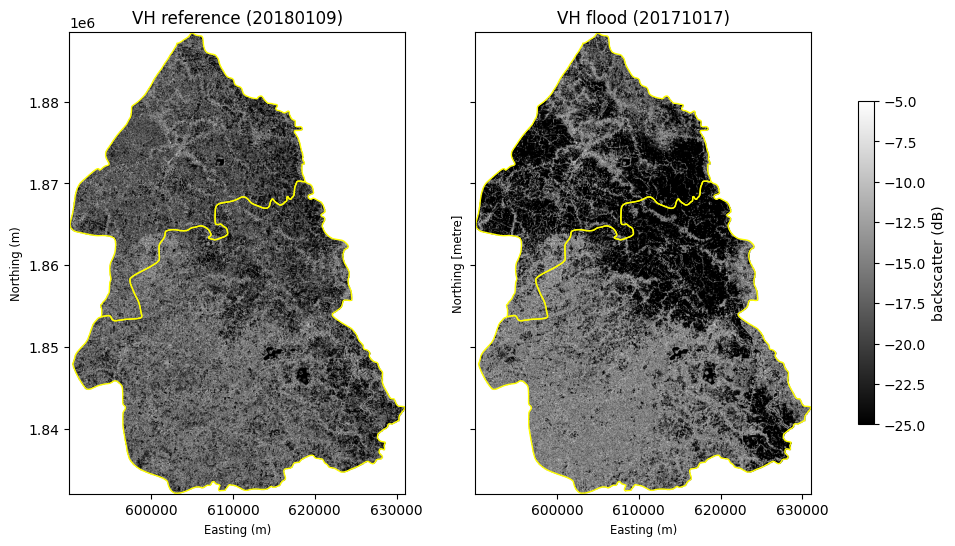

In [26]:
if os.path.isdir(OUT_DIR):
    bnd = gpd.read_file(f'{OUT_DIR}/boundary_amphoe.geojson').to_crs(CRS)
    fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
    for ax, tag, title in zip(axes, [r_tag, f_tag], ['reference', 'flood']):
        with rasterio.open(f'{OUT_DIR}/S1_{tag}_VH.tif') as src:
            # อ่านแบบย่อ 1/8 เพื่อประหยัดหน่วยความจำ
            arr = src.read(1, out_shape=(src.height // 8, src.width // 8), masked=True) / 100.0
            b = src.bounds
        im = ax.imshow(arr, cmap='gray', vmin=-25, vmax=-5, extent=[b.left, b.right, b.bottom, b.top])
        bnd.boundary.plot(ax=ax, color='yellow', linewidth=1)
        ax.set_title(f'VH {title} ({tag})')
        ax.set_xlabel('Easting (m)')
    axes[0].set_ylabel('Northing (m)')
    fig.colorbar(im, ax=axes, shrink=0.7, label='backscatter (dB)')
    plt.show()

### นำขึ้น GitHub
1. ดาวน์โหลดโฟลเดอร์ `/content/data` จากแถบไฟล์ด้านซ้ายของ Colab
2. วางไฟล์ในโฟลเดอร์ `data/` ของ repository `Teach_SAR_flood_Mapping_ML` และวาง `sarflood_utils.py` กับ notebook ทั้งหมดไว้ที่ระดับบนสุดของ repository
3. ไฟล์ที่ไม่เกิน 25 MB อัปโหลดผ่านหน้าเว็บได้ ไฟล์ที่ใหญ่กว่านั้นใช้ `git add`, `git commit`, `git push`

## 7. แบบฝึกหัด

### ข้อ 1 อ่าน metadata
จากตาราง `meta` ในส่วนที่ 4 ภาพทั้งสองวันถ่ายด้วยดาวเทียมดวงใด ทิศการโคจรใด และ relative orbit เท่าไร ถ้า relative orbit ของสองวันไม่ตรงกัน จะเกิดปัญหาอะไรกับการตรวจจับน้ำท่วม

<details><summary><b>เฉลย</b></summary>

อ่านค่าจากคอลัมน์ `platform_number`, `orbitProperties_pass` และ `relativeOrbitNumber_start`
ถ้า orbit ไม่ตรงกัน มุมตกกระทบ ณ จุดเดียวกันจะต่างกัน ทำให้ค่า backscatter เปลี่ยนแม้พื้นผิวเหมือนเดิม การหาความต่างของภาพจึงเกิดสัญญาณหลอก (false positive) โดยเฉพาะบริเวณที่มีความลาดชันและสิ่งปลูกสร้าง UN-SPIDER ระบุข้อนี้เป็นข้อจำกัดหนึ่งของวิธีการ
</details>

### ข้อ 2 ประมาณขนาดไฟล์
สมมติกรอบสี่เหลี่ยมของพื้นที่ศึกษากว้าง 60 กม. สูง 45 กม. ที่ความละเอียด 10 ม. จะมีกี่จุดภาพ และถ้าเก็บแบบ int16 โดยไม่บีบอัดจะใช้กี่ MB ต่อแบนด์ ถ้าเปลี่ยนเป็น 20 ม. จะเหลือเท่าไร

<details><summary><b>เฉลย</b></summary>

- จำนวนจุดภาพ = (60,000 / 10) × (45,000 / 10) = 6,000 × 4,500 = 27,000,000 จุดภาพ
- int16 ใช้ 2 ไบต์ต่อจุดภาพ จึงเท่ากับ 54,000,000 ไบต์ หรือ 54 MB
- ที่ 20 ม. จำนวนจุดภาพลดลง 4 เท่า เหลือ 6,750,000 จุดภาพ หรือ 13.5 MB

ขนาดจริงเล็กกว่านี้เพราะมีการบีบอัด และจุดภาพนอกขอบเขตอำเภอเป็น nodata ซึ่งบีบอัดได้เกือบทั้งหมด เทียบกับตารางในส่วนที่ 6 ได้
</details>

### ข้อ 3 คิดต่อ
ภาพอ้างอิงถ่ายเดือนมกราคมซึ่งเป็นฤดูแล้งหลังเก็บเกี่ยวข้าว ส่วนภาพน้ำท่วมถ่ายเดือนตุลาคม นอกจากน้ำท่วมแล้ว มีอะไรอีกบ้างที่ทำให้ backscatter ของสองวันต่างกัน และจะส่งผลต่อแผนที่น้ำท่วมอย่างไร

<details><summary><b>เฉลย</b></summary>

- **พืชพรรณ:** ต.ค. ข้าวกำลังโตหรือใกล้เก็บเกี่ยว ม.ค. เป็นตอซังหรือดินเปล่า โครงสร้างพืชที่ต่างกันทำให้ VH เปลี่ยนมาก
- **ความชื้นดิน:** ดินเปียกปลายฤดูฝนสะท้อนแรงกว่าดินแห้งในฤดูแล้ง
- **นาปรัง:** แปลงที่ขังน้ำเตรียมปลูกในเดือน ม.ค. จะมืดในภาพอ้างอิง ทำให้พื้นที่นั้นดูเหมือนไม่เปลี่ยนแปลง

ผลคือแผนที่อาจมีทั้งส่วนที่ตรวจเกิน (การเปลี่ยนแปลงที่ไม่ใช่น้ำท่วม) และส่วนที่ตรวจขาด เราจะกลับมาวิเคราะห์ประเด็นนี้ใน notebook 02
</details>

## สรุป
- ตั้งค่า GEE ด้วย project ของตนเอง และรวมพารามิเตอร์ไว้ที่เดียว
- ตรวจ metadata ของ Sentinel-1 ทั้งวันที่ ทิศการโคจร relative orbit และความครอบคลุม ก่อนเปรียบเทียบภาพ
- ข้อมูลทั้งหมดอยู่ในระบบพิกัด UTM 47N และเก็บแบบจำนวนเต็มบีบอัดเพื่อให้อยู่ใน GitHub ได้

**ถัดไป:** `01` หลักการภาพ SAR, polarization และภาพผสมสี

## เอกสารอ้างอิง
- UN-SPIDER. Recommended Practice: Flood Mapping and Damage Assessment Using Sentinel-1 SAR Data in Google Earth Engine.
- Notti, D. et al. (2018). Potential and Limitations of Open Satellite Data for Flood Mapping. *Remote Sensing*, 10, 1673. https://doi.org/10.3390/rs10111673